# ECE 662 Team 9: Storage and Accuracy–Hardware Tradeoffs

**Owner:** Josie Barber

**Goal:** How much efficiency do we gain for the accuracy we give up?

This notebook:
1. Rebuilds the shared pipeline (shared checkpoint, 64×64 input, BN folding, per-channel symmetric weights, fixed 8-bit activations) and checks it against known numbers.
2. Calculates deployed storage for uniform W8A8, uniform W4A8 and Lilly's top-k configs, including scales, biases and metadata.
3. Independently checks the accuracy of every config on the full 10,000-image test set.
4. Merges accuracy, storage and Dana's NeuroSim energy, latency and area into one table, with differences relative to W8A8.
5. Plots accuracy vs. storage and accuracy vs. energy and marks the Pareto-optimal configs.

**Extra packages:** none beyond torch, torchvision, pandas, matplotlib, jupyter and ipykernel.

**Outputs** (all written to `results/josie/`): `storage_analysis.csv`, `storage_by_layer.csv`, `accuracy_validation.csv`, `final_comparison.csv`, `accuracy_storage_pareto.png`, and `accuracy_energy_pareto.png` (one per depthwise mapping if Dana reports two).

## 1. Setup

In [3]:
import os, sys, subprocess
import torch
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/josie-barber/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators.git"
if IN_COLAB:
    REPO_DIR = "/content/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
else:
    REPO_DIR = os.path.abspath(".")
CKPT_PATH = os.path.join(REPO_DIR, "mobilenetv2_cifar10-2.pth")
DATA_DIR = os.path.join(REPO_DIR, "data")
OUT_DIR = os.path.join(REPO_DIR, "results", "josie")
os.makedirs(OUT_DIR, exist_ok=True)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
NUM_WORKERS = 2 if IN_COLAB else 0
PIN_MEMORY = device.type == "cuda"
print(f"Colab: {IN_COLAB} | device: {device} | repo: {REPO_DIR}")

Colab: False | device: mps | repo: /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators


In [4]:
import copy
import json
import math
import random
import re
import time

import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.nn.utils import fuse_conv_bn_eval
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v2

# ---------------- Input files (every path in one place) ----------------
LILLY_DIR = os.path.join(REPO_DIR, "ECE662_results_A8")
CONFIGS_PATH = os.path.join(LILLY_DIR, "mixed_precision_configs.json")      # Lilly: top-k bit-widths
LILLY_ACC_PATH = os.path.join(LILLY_DIR, "accuracy_A8_for_merge.csv")       # Lilly: A8 accuracy
DANA_HW_PATH = os.path.join(REPO_DIR, "neurosim_final_results.csv")          # Dana: A8 NeuroSim results
AMANDA_RESULTS_PATH = os.path.join(REPO_DIR, "results", "a8_results.csv")    # Amanda (read-only)
AMANDA_CONFIGS_PATH = os.path.join(REPO_DIR, "results", "amanda_neurosim_configs.json")  # Amanda (read-only)

# ---------------- Settings ----------------
SEED = 42
BATCH_SIZE = 128
REQUIRED_K = [10, 20, 30, 40]   # top-k configs the work plan asks for
CALIB_IMAGES = 2048             # training images for Josie's per-config calibration
LILLY_CALIB_IMAGES = 1024       # Lilly's calibration subset (training split, subset seed 662)
ACT_BITS = 8
ACT_QUANTIZER = "lilly"         # "lilly" (team quantizer from notebook 03) or "josie" (per-config calibration)
ONE_PP = 1.0                    # target: within 1 percentage point of W8A8

# Known numbers from the midterm / team runs (full test set). The notebook stops if these don't match.
EXPECTED_PCT = {"FP32": 89.82, "W8 / FP32 act": 89.87, "W4 / FP32 act": 17.58, "W8A8": 89.80}
TOLERANCE_PP = {"FP32": 0.15, "W8 / FP32 act": 0.15, "W4 / FP32 act": 1.0, "W8A8": 0.2}
VALIDATION_TOL_PP = 0.2         # flag configs where my accuracy differs from Lilly's by more than this

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

FILES_WRITTEN = []


def save_csv(df, filename):
    path = os.path.join(OUT_DIR, filename)
    df.to_csv(path, index=False)
    FILES_WRITTEN.append(path)
    print(f"Saved {path}")


for label, path in [("Lilly configs", CONFIGS_PATH), ("Lilly A8 accuracy", LILLY_ACC_PATH),
                    ("Dana NeuroSim", DANA_HW_PATH), ("Amanda A8 results", AMANDA_RESULTS_PATH),
                    ("Amanda configs", AMANDA_CONFIGS_PATH)]:
    print(f"{label:18s} {'found  ' if os.path.exists(path) else 'MISSING'}  {path}")

Lilly configs      found    /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/ECE662_results_A8/mixed_precision_configs.json
Lilly A8 accuracy  found    /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/ECE662_results_A8/accuracy_A8_for_merge.csv
Dana NeuroSim      MISSING  /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/neurosim_final_results.csv
Amanda A8 results  found    /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results/a8_results.csv
Amanda configs     found    /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results/amanda_neurosim_configs.json


## 2. Data

Same preprocessing as the team pipeline: resize to 64×64, then ImageNet mean/std. Calibration only ever uses training images, never validation or test: Lilly's quantizer uses her 1,024-image subset (seed 662), and the alternative `josie` quantizer uses the first 2,048 images of the training split.

In [5]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_full = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=eval_transform)
test_set = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=eval_transform)

# Team split: seeded permutation, first 45,000 = train, last 5,000 = validation
split = torch.randperm(50000, generator=torch.Generator().manual_seed(42))
train_indices = split[:45000].tolist()
val_indices = split[45000:].tolist()
calib_indices = train_indices[:CALIB_IMAGES]
assert not set(calib_indices) & set(val_indices)

loader_kwargs = dict(batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
calib_loader = DataLoader(Subset(train_full, calib_indices), **loader_kwargs)

# Lilly's calibration subset (notebook 03): 1,024 training images chosen with seed 662
calib_perm = torch.randperm(len(train_indices), generator=torch.Generator().manual_seed(662))
lilly_calib_indices = [train_indices[i] for i in calib_perm[:LILLY_CALIB_IMAGES].tolist()]
assert not set(lilly_calib_indices) & set(val_indices)
lilly_calib_loader = DataLoader(Subset(train_full, lilly_calib_indices), **loader_kwargs)
test_loader = DataLoader(test_set, **loader_kwargs)

print(f"Calibration: {len(calib_indices):,} training images | Test: {len(test_set):,} images")

Calibration: 2,048 training images | Test: 10,000 images


## 3. Load the shared checkpoint and fold BatchNorm

In [6]:
base_model = mobilenet_v2(weights=None)
base_model.classifier[1] = nn.Linear(base_model.last_channel, 10)
base_model.load_state_dict(torch.load(CKPT_PATH, map_location="cpu", weights_only=True), strict=True)
base_model.eval()


def fold_batch_norm(model):
    """Fold each Conv2d -> BatchNorm2d pair (same as the team notebook). Layer names stay the same."""
    folded = copy.deepcopy(model).eval()
    pairs = []

    def visit(module, prefix=""):
        for name, child in list(module.named_children()):
            visit(child, f"{prefix}.{name}" if prefix else name)
        if isinstance(module, nn.Sequential):
            children = list(module.named_children())
            for i in range(len(children) - 1):
                conv_name, conv = children[i]
                bn_name, bn = children[i + 1]
                if isinstance(conv, nn.Conv2d) and isinstance(bn, nn.BatchNorm2d):
                    module._modules[conv_name] = fuse_conv_bn_eval(conv, bn)
                    module._modules[bn_name] = nn.Identity()
                    pairs.append(f"{prefix}.{conv_name}" if prefix else conv_name)

    visit(folded)
    if any(isinstance(m, nn.BatchNorm2d) for m in folded.modules()):
        raise RuntimeError("Some BatchNorm layers were not folded.")
    return folded, pairs


folded_model, folded_pairs = fold_batch_norm(base_model)   # stays on CPU as the master copy

LAYERS = {n: m for n, m in folded_model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))}
LAYER_NAMES = list(LAYERS)
assert len(folded_pairs) == 52, f"expected 52 folded BN layers, got {len(folded_pairs)}"
assert len(LAYER_NAMES) == 53, f"expected 53 quantizable layers, got {len(LAYER_NAMES)}"


def layer_type(name, layer):
    if isinstance(layer, nn.Linear):
        return "fc"
    if layer.groups > 1:
        return "depthwise"
    if name == "features.0.0":
        return "first_conv"
    if name == "features.18.0":
        return "final_1x1"
    if name.endswith(".conv.2") or name.endswith(".conv.1"):
        return "projection_1x1"
    return "expansion_1x1"


LAYER_TYPES = {n: layer_type(n, m) for n, m in LAYERS.items()}
print(f"Folded {len(folded_pairs)} BN layers | {len(LAYER_NAMES)} quantizable layers")
print(pd.Series(LAYER_TYPES).value_counts().to_string())

Folded 52 BN layers | 53 quantizable layers
depthwise         17
projection_1x1    17
expansion_1x1     16
first_conv         1
final_1x1          1
fc                 1


## 4. Weight quantization

Per-output-channel symmetric weights, integer range ±(2^(b−1)−1), identical to the team's `quantize_weights`. The math runs on the CPU master copy, then the model moves to the device.

In [7]:
def quantize_weights(weights, bits):
    if bits not in (4, 8):
        raise ValueError("bits must be 4 or 8")
    qmax = 2 ** (bits - 1) - 1
    reduce_dims = tuple(range(1, weights.ndim))
    max_abs = weights.abs().amax(dim=reduce_dims, keepdim=True)
    scale = torch.where(max_abs > 0, max_abs / qmax, torch.ones_like(max_abs))
    return torch.clamp(torch.round(weights / scale), -qmax, qmax) * scale


def check_bit_config(bit_config):
    if set(bit_config) != set(LAYER_NAMES):
        missing = set(LAYER_NAMES) - set(bit_config)
        extra = set(bit_config) - set(LAYER_NAMES)
        raise ValueError(f"bit config must list all 53 layers (missing {len(missing)}, unknown {len(extra)})")
    if any(b not in (4, 8) for b in bit_config.values()):
        raise ValueError("every layer must be 4 or 8 bits")


def quantize_model_by_layer(bit_config):
    """Fresh copy of the folded model with per-layer weight bit-widths (None = keep FP32 weights)."""
    model = copy.deepcopy(folded_model).eval()
    if bit_config is not None:
        check_bit_config(bit_config)
        with torch.no_grad():
            for name, layer in model.named_modules():
                if name in bit_config:
                    layer.weight.copy_(quantize_weights(layer.weight, bit_config[name]))
    return model.to(device)


ALL_W8 = {n: 8 for n in LAYER_NAMES}
ALL_W4 = {n: 4 for n in LAYER_NAMES}
print("Weight quantization ready.")

Weight quantization ready.


## 5. Fixed 8-bit activation quantization (one switchable function)

Every Conv2d/Linear **input** is fake-quantized per tensor with a static min/max range from training images. Non-negative inputs (after ReLU6) use unsigned codes [0, 255]; signed inputs (the normalized image and the residual stream) use symmetric codes [−127, 127]. The zero point is 0 in both cases.

- **`lilly` (default, the team quantizer):** Lilly's notebook 03 cell, copied as-is. Ranges are calibrated **once** on the folded FP32 model with her 1,024 calibration images, then the same ranges are used for every config.
- **`josie`:** same math, but ranges are recalibrated for each config on its weight-quantized model with 2,048 images. Gives W8A8 = 89.66% vs. 89.80% for `lilly`.

In [8]:
def josie_act_quant(model, calib_loader, bits=ACT_BITS):
    layers = {n: m for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))}
    lo = {n: None for n in layers}
    hi = {n: None for n in layers}

    def observer(name):
        def hook(module, inputs):
            x = inputs[0].detach()
            mn, mx = x.amin(), x.amax()
            lo[name] = mn if lo[name] is None else torch.minimum(lo[name], mn)
            hi[name] = mx if hi[name] is None else torch.maximum(hi[name], mx)
        return hook

    handles = [m.register_forward_pre_hook(observer(n)) for n, m in layers.items()]
    model.eval()
    with torch.inference_mode():
        for images, _ in calib_loader:
            model(images.to(device))
    for h in handles:
        h.remove()

    qparams = {}
    for n in layers:
        mn, mx = lo[n].item(), hi[n].item()
        if mn >= 0:                                   # unsigned
            qmin, qmax = 0, 2 ** bits - 1
            scale = mx / qmax
        else:                                         # signed symmetric
            qmax = 2 ** (bits - 1) - 1
            qmin = -qmax
            scale = max(-mn, mx) / qmax
        qparams[n] = (scale if scale > 0 else 1.0, qmin, qmax)

    def quantizer(name):
        scale, qmin, qmax = qparams[name]

        def hook(module, inputs):
            x = torch.clamp(torch.round(inputs[0] / scale), qmin, qmax) * scale
            return (x,) + tuple(inputs[1:])
        return hook

    model._act_quant_handles = [m.register_forward_pre_hook(quantizer(n)) for n, m in layers.items()]
    model.act_qparams = qparams
    return model


# ===================== Team 9 activation quantizer (copy this cell as-is) =====================
def fake_quantize_activation(x, lo, hi, bits=8):
    # Static per-tensor fake quantization. Unsigned if lo >= 0, otherwise signed symmetric.
    if lo >= 0:
        qmax = 2 ** bits - 1
        scale = max(hi, 1e-12) / qmax
        return torch.clamp(torch.round(x / scale), 0, qmax) * scale
    qmax = 2 ** (bits - 1) - 1
    scale = max(abs(lo), abs(hi), 1e-12) / qmax
    return torch.clamp(torch.round(x / scale), -qmax, qmax) * scale


def calibrate_activation_ranges(model, loader, names, method="minmax", percentile=99.99):
    # Record the input range of each named layer on the calibration data.
    modules = dict(model.named_modules())
    stats = {n: {"min": [], "max": [], "pct": []} for n in names}
    def make_hook(n):
        def hook(_m, inputs):
            x = inputs[0].detach()
            stats[n]["min"].append(x.min().item())
            stats[n]["max"].append(x.max().item())
            if method == "percentile":
                flat = x.flatten().float()
                if flat.numel() > 1_000_000:  # torch.quantile has a size limit
                    flat = flat[torch.randperm(flat.numel(), device=flat.device)[:1_000_000]]
                stats[n]["pct"].append(torch.quantile(flat.abs(), percentile / 100).item())
        return hook
    handles = [modules[n].register_forward_pre_hook(make_hook(n)) for n in names]
    model.eval()
    device_ = next(model.parameters()).device
    with torch.inference_mode():
        for images, _ in loader:
            model(images.to(device_))
    for h in handles:
        h.remove()
    ranges = {}
    for n in names:
        lo, hi = min(stats[n]["min"]), max(stats[n]["max"])
        if method == "percentile":
            p = float(np.mean(stats[n]["pct"]))
            lo, hi = (0.0, min(hi, p)) if lo >= 0 else (-p, p)
        ranges[n] = (float(lo), float(hi))
    return ranges


def attach_activation_quant(model, ranges, bits=8, mode="static"):
    # Add fake activation quantization at the input of every layer in `ranges`. Returns hook handles.
    modules = dict(model.named_modules())
    handles = []
    for n, (lo, hi) in ranges.items():
        signed = lo < 0
        def hook(_m, inputs, lo=lo, hi=hi, signed=signed):
            x = inputs[0]
            if mode == "dynamic":
                x_lo, x_hi = x.min().item(), x.max().item()
                x_lo = min(x_lo, -1e-12) if signed else 0.0
                return (fake_quantize_activation(x, x_lo, x_hi, bits),) + tuple(inputs[1:])
            return (fake_quantize_activation(x, lo, hi, bits),) + tuple(inputs[1:])
        handles.append(modules[n].register_forward_pre_hook(hook))
    return handles
# ==========================================================================================
_LILLY_RANGES = None


def lilly_act_quant(model, calib_loader, bits=ACT_BITS):
    """Lilly's method: ranges from the folded FP32 model on her calibration subset, shared by every config."""
    global _LILLY_RANGES
    if _LILLY_RANGES is None:
        fp32 = copy.deepcopy(folded_model).to(device)
        _LILLY_RANGES = calibrate_activation_ranges(fp32, lilly_calib_loader, LAYER_NAMES, method="minmax")
        del fp32
    model._act_quant_handles = attach_activation_quant(model, _LILLY_RANGES, bits=bits)
    model.act_qparams = _LILLY_RANGES
    return model


ACT_QUANTIZERS = {"josie": josie_act_quant, "lilly": lilly_act_quant}


def build_model(bit_config, a8=True):
    """bit_config: dict layer->bits, or None for FP32 weights. a8: apply fixed 8-bit activations."""
    model = quantize_model_by_layer(bit_config)
    if a8:
        model = ACT_QUANTIZERS[ACT_QUANTIZER](model, calib_loader, ACT_BITS)
    return model


def evaluate(model, loader):
    model.eval()
    correct = total = 0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    if total == 0:
        raise ValueError("The data loader contains no images.")
    return 100.0 * correct / total


print(f"Activation quantizer: {ACT_QUANTIZER} | A{ACT_BITS}")

Activation quantizer: lilly | A8


## 6. Sanity check (stops on mismatch)

In [9]:
t0 = time.time()
sanity = {
    "FP32": evaluate(build_model(None, a8=False), test_loader),
    "W8 / FP32 act": evaluate(build_model(ALL_W8, a8=False), test_loader),
    "W4 / FP32 act": evaluate(build_model(ALL_W4, a8=False), test_loader),
    "W8A8": evaluate(build_model(ALL_W8, a8=True), test_loader),
}
rows = []
for key, acc in sanity.items():
    diff = acc - EXPECTED_PCT[key]
    rows.append({"check": key, "measured_pct": acc, "expected_pct": EXPECTED_PCT[key],
                 "diff_pp": diff, "ok": abs(diff) <= TOLERANCE_PP[key]})
sanity_df = pd.DataFrame(rows)
print(sanity_df.round(2).to_string(index=False))
print(f"({time.time() - t0:.0f} s)")

failed = sanity_df[~sanity_df["ok"]]
if len(failed):
    raise RuntimeError(
        "Sanity check failed for: " + ", ".join(failed["check"]) + ". The pipeline does not match the team's. "
        "Check the checkpoint, data and preprocessing. If only W8A8 fails, the activation quantizer differs "
        "from the one that produced 89.7%: paste Lilly's quantizer into section 5 and set ACT_QUANTIZER = 'lilly'.")
print("Sanity check passed.")

        check  measured_pct  expected_pct  diff_pp   ok
         FP32         89.82         89.82     0.00 True
W8 / FP32 act         89.87         89.87     0.00 True
W4 / FP32 act         17.58         17.58     0.00 True
         W8A8         89.87         89.80     0.07 True
(23 s)
Sanity check passed.


## 7. Load configs

The top-k layer sets come **directly from Lilly's `ECE662_results_A8/mixed_precision_configs.json`** and are never recomputed here. Amanda's configs (whole-block protection, her own top-k sweep, and bias-corrected versions) get storage numbers here; their accuracy comes from her `a8_results.csv`, because bias correction isn't reproduced here.

In [10]:
def norm_key(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


W8_ALIASES = {"w8a8", "int8", "w8", "uniformw8", "uniformint8", "uniformw8a8", "allw8", "int8a8", "8bit"}
W4_ALIASES = {"w4a8", "int4", "w4", "uniformw4", "uniformint4", "uniformw4a8", "allw4", "int4a8", "4bit"}


def canonical(name):
    """One name per config so teammates' files can be matched (e.g. 'k_10', 'top10', 10 -> 'k_10')."""
    if isinstance(name, (int, np.integer)) or (isinstance(name, float) and float(name).is_integer()):
        name = f"k_{int(name)}"
    key = norm_key(name)
    if key in W8_ALIASES:
        return "W8A8"
    if key in W4_ALIASES:
        return "W4A8"
    m = re.fullmatch(r"(?:topk|top|k)(\d+)(?:a8|w8a8|w4a8)?", key)
    if m:
        k = int(m.group(1))
        return "W4A8" if k == 0 else "W8A8" if k == len(LAYER_NAMES) else f"k_{k}"
    return str(name).strip()


def extract_bit_config(obj):
    """Find a {layer: bits} dict in a config entry (plain dict, or nested under a key like 'bits')."""
    if isinstance(obj, dict):
        layer_bits = {k: v for k, v in obj.items() if k in LAYERS}
        if len(layer_bits) == len(LAYER_NAMES):
            return {k: int(v) for k, v in layer_bits.items()}
        for value in obj.values():
            found = extract_bit_config(value)
            if found:
                return found
    return None


CONFIGS = {"W8A8": ALL_W8, "W4A8": ALL_W4}
CONFIG_SOURCE = {"W8A8": "uniform", "W4A8": "uniform"}


def add_configs(path, source):
    with open(path) as f:
        raw = json.load(f)
    if isinstance(raw.get("configs"), dict):      # Lilly's layout: {"layer_order", "act_bits", "configs": {...}}
        raw = raw["configs"]
    for name, entry in raw.items():
        bits = extract_bit_config(entry)
        if bits is None or any(b not in (4, 8) for b in bits.values()):
            print(f"  skipped {name}: no complete 53-layer 4/8-bit assignment")
            continue
        cname = canonical(name)
        uniform = "W8A8" if all(b == 8 for b in bits.values()) else "W4A8" if all(b == 4 for b in bits.values()) else None
        # A uniform model is the same as W8A8/W4A8 unless something else changes it (e.g. Amanda's bias correction)
        if uniform and (source == "lilly" or cname == uniform):
            if name != uniform:
                print(f"  {name} is the same model as {uniform}; using {uniform}")
            continue
        if cname in CONFIGS:
            if CONFIGS[cname] != bits:
                print(f"  WARNING: {name} from {source} conflicts with an existing '{cname}'; kept the first one")
            continue
        CONFIGS[cname] = bits
        CONFIG_SOURCE[cname] = source


if os.path.exists(CONFIGS_PATH):
    print("Lilly's configs:")
    add_configs(CONFIGS_PATH, "lilly")
else:
    print(f"SKIP: {CONFIGS_PATH} not found. Only uniform W8A8/W4A8 will be analyzed.")

if os.path.exists(AMANDA_CONFIGS_PATH):
    print("Amanda's configs:")
    add_configs(AMANDA_CONFIGS_PATH, "amanda")
else:
    print(f"SKIP: {AMANDA_CONFIGS_PATH} not found (Amanda's configs are optional).")


def k_of(name):
    m = re.fullmatch(r"k_(\d+)", name)
    return int(m.group(1)) if m else None


missing_k = [k for k in REQUIRED_K if f"k_{k}" not in CONFIGS]
if missing_k:
    print(f"\nNOTE: Lilly's configs file does not have k = {missing_k} yet. Rerun once she adds them.")

# Order: W8A8, top-k by decreasing k, W4A8, then anything else
order = (["W8A8"] + sorted([c for c in CONFIGS if k_of(c) is not None], key=k_of, reverse=True)
         + ["W4A8"] + [c for c in CONFIGS if c not in ("W8A8", "W4A8") and k_of(c) is None])
CONFIGS = {c: CONFIGS[c] for c in order}
print("\nConfigs:", ", ".join(f"{c} ({sum(b == 8 for b in v.values())}×W8)" for c, v in CONFIGS.items()))

Lilly's configs:
Amanda's configs:
  Uniform | W8 is the same model as W8A8; using W8A8

Configs: W8A8 (53×W8), k_40 (40×W8), k_30 (30×W8), k_20 (20×W8), k_10 (10×W8), k_5 (5×W8), k_3 (3×W8), k_1 (1×W8), W4A8 (0×W8), Uniform | W4 + bias correction (0×W8), Whole blocks + bias correction | Block 1 only (2×W8), Whole blocks + bias correction | Blocks 0-1 (3×W8), Whole blocks + bias correction | Blocks 0-2 (6×W8), Whole blocks + bias correction | Blocks 0-3 (9×W8), Whole blocks + bias correction | Blocks 0-4 (12×W8), Whole blocks + bias correction | Blocks 0-5 (15×W8), Whole blocks + bias correction | Blocks 0-7 (21×W8), Top-k + bias correction | Top-30 (30×W8), Top-k | Top-34 (34×W8), Top-k | Top-40 (40×W8), Top-k | Top-42 (42×W8), Top-k | Top-43 (43×W8), Top-k | Top-45 (45×W8), Top-k | Top-46 (46×W8), Whole blocks | Block 1 only (2×W8), Whole blocks | Blocks 0-1 (3×W8), Whole blocks | Blocks 1-2 (5×W8), Whole blocks | Blocks 0-2 (6×W8), Whole blocks | Blocks 0-3 (9×W8), Whole blocks | Bl

## 8. Storage accounting

**Counted for each layer:**

| Item | Size | Why |
|---|---|---|
| Weights | ceil(n_weights × bits / 8) bytes | Packed: 2 INT4 or 1 INT8 weight per byte, padded to a whole byte at the end of each layer |
| Per-channel weight scales | out_channels × 4 bytes | One FP32 scale per output channel |
| Biases | out_channels × 4 bytes | FP32. Every conv has a bias after BN folding, and the classifier has its own |
| Bit-width metadata | 1 byte | Each layer's 4/8 tag |
| Weight zero points | 0 bytes | Symmetric quantization, so there is no zero point |
| Activation quantization parameters | 5 bytes | One FP32 per-tensor scale plus a 1-byte signed/unsigned flag for the layer input (zero point is 0) |

**Not counted:** activation and feature-map buffers, residual-add buffers, im2col or other runtime workspace, the network description (shapes, strides, layer order), runtime code, BatchNorm running statistics (folded away), and the FP32 master weights. On-chip buffer and peripheral cost is a hardware-area question, covered by Dana's NeuroSim area numbers.

All sizes use decimal MB (10⁶ bytes) to match the team's earlier tables. `weight_payload_MB` is the midterm's weights-only number, kept for comparison.

In [11]:
SCALE_BYTES = 4
BIAS_BYTES = 4
BITWIDTH_META_BYTES = 1
ACT_QPARAM_BYTES = 4 + 1


def layer_storage(name, bits):
    layer = LAYERS[name]
    out_ch = layer.weight.shape[0]
    n_bias = layer.bias.numel() if layer.bias is not None else 0
    return {
        "weight_bytes": math.ceil(layer.weight.numel() * bits / 8),
        "scale_bytes": out_ch * SCALE_BYTES,
        "bias_bytes": n_bias * BIAS_BYTES,
        "metadata_bytes": BITWIDTH_META_BYTES,
        "act_qparam_bytes": ACT_QPARAM_BYTES,
    }


def config_storage(bit_config):
    check_bit_config(bit_config)
    totals = {}
    for name, bits in bit_config.items():
        for key, value in layer_storage(name, bits).items():
            totals[key] = totals.get(key, 0) + value
    totals["total_bytes"] = sum(totals.values())
    return totals


fp32_reference_bytes = sum(p.numel() * 4 for p in folded_model.parameters())
storage_rows = []
for cname, bits in CONFIGS.items():
    s = config_storage(bits)
    storage_rows.append({
        "config": cname,
        "source": CONFIG_SOURCE[cname],
        "k": len(LAYER_NAMES) if cname == "W8A8" else 0 if cname == "W4A8" else k_of(cname),
        "n_layers_w8": sum(b == 8 for b in bits.values()),
        "n_layers_w4": sum(b == 4 for b in bits.values()),
        **s,
        "weight_payload_MB": s["weight_bytes"] / 1e6,
        "total_MB": s["total_bytes"] / 1e6,
        "overhead_pct_of_total": 100 * (s["total_bytes"] - s["weight_bytes"]) / s["total_bytes"],
    })
storage_df = pd.DataFrame(storage_rows)
w8_total = storage_df.loc[storage_df["config"] == "W8A8", "total_bytes"].item()
storage_df["total_vs_W8A8_pct"] = 100 * (storage_df["total_bytes"] / w8_total - 1)
storage_df["compression_vs_FP32_x"] = fp32_reference_bytes / storage_df["total_bytes"]
save_csv(storage_df, "storage_analysis.csv")

# Per-layer table (useful for the depthwise discussion)
layer_rows = []
for name in LAYER_NAMES:
    s8, s4 = layer_storage(name, 8), layer_storage(name, 4)
    layer_rows.append({"layer": name, "type": LAYER_TYPES[name],
                       "n_weights": LAYERS[name].weight.numel(),
                       "out_channels": LAYERS[name].weight.shape[0],
                       "total_bytes_w8": sum(s8.values()), "total_bytes_w4": sum(s4.values()),
                       "bytes_saved_w8_to_w4": sum(s8.values()) - sum(s4.values())})
layer_df = pd.DataFrame(layer_rows)
save_csv(layer_df, "storage_by_layer.csv")

print(f"\nFP32 reference (folded model, all parameters): {fp32_reference_bytes / 1e6:.3f} MB")
show = ["config", "n_layers_w8", "weight_payload_MB", "total_MB", "overhead_pct_of_total", "total_vs_W8A8_pct"]
print(storage_df[show].round(4).to_string(index=False))
print("\nStorage share by layer type at W8A8:")
by_type = layer_df.groupby("type")[["n_weights", "total_bytes_w8", "bytes_saved_w8_to_w4"]].sum()
by_type["share_of_w8_total_pct"] = 100 * by_type["total_bytes_w8"] / by_type["total_bytes_w8"].sum()
print(by_type.round(1).to_string())

Saved /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results/josie/storage_analysis.csv
Saved /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results/josie/storage_by_layer.csv

FP32 reference (folded model, all parameters): 8.879 MB
                                       config  n_layers_w8  weight_payload_MB  total_MB  overhead_pct_of_total  total_vs_W8A8_pct
                                         W8A8           53             2.2026    2.3394                 5.8496             0.0000
                                         k_40           40             1.9565    2.0933                 6.5373           -10.5193
                                         k_30           30             1.6444    1.7813                 7.6824           -23.8573
                                         k_20           20             1.4484    1.5853                 8.6324           -32.2369
                                   

## 9. Independent accuracy check

Every uniform config and every config from Lilly's file is rebuilt and evaluated here with fixed A8 on the full test set. If Lilly's `mixed_precision_A8.csv` is present, each result is compared with hers.

In [12]:
def find_col(df, patterns, exclude=()):
    """First column whose normalized name contains a pattern (patterns tried in order)."""
    cols = {c: norm_key(c) for c in df.columns}
    for p in patterns:
        for c, key in cols.items():
            if p in key and not any(e in key for e in exclude):
                return c
    return None


def read_teammate_accuracy(path, who):
    """Return {canonical config: accuracy %} from a teammate CSV, or {} with a message."""
    if not os.path.exists(path):
        print(f"SKIP: {who}'s file not found ({path})")
        return {}
    df = pd.read_csv(path)
    cfg_col = find_col(df, ["config", "protectedw8layers", "model", "name", "precision", "setting"])
    if cfg_col is None and "k" in df.columns:
        cfg_col = "k"
    acc_col = find_col(df, ["testaccuracy", "accuracy", "acc"],
                       exclude=["drop", "diff", "delta", "std", "ci", "validation", "val"])
    if cfg_col is None or acc_col is None:
        print(f"SKIP: couldn't find config/accuracy columns in {who}'s file. Columns: {list(df.columns)}")
        return {}
    out = {canonical(c): float(a) for c, a in zip(df[cfg_col], df[acc_col]) if pd.notna(a)}
    print(f"{who}: read {len(out)} accuracies from columns '{cfg_col}' / '{acc_col}'")
    return out


lilly_acc = read_teammate_accuracy(LILLY_ACC_PATH, "Lilly")
amanda_acc = read_teammate_accuracy(AMANDA_RESULTS_PATH, "Amanda")

my_acc = {"W8A8": sanity["W8A8"]}
for cname in CONFIGS:
    if cname in my_acc or CONFIG_SOURCE[cname] == "amanda":
        continue
    t0 = time.time()
    model = build_model(CONFIGS[cname], a8=True)
    my_acc[cname] = evaluate(model, test_loader)
    del model
    print(f"{cname:8s} {my_acc[cname]:6.2f}%  ({time.time() - t0:.0f} s)", flush=True)

val_rows = []
for cname in CONFIGS:
    mine = my_acc.get(cname)
    theirs = lilly_acc.get(cname)
    diff = mine - theirs if mine is not None and theirs is not None else None
    val_rows.append({"config": cname, "my_accuracy_pct": mine, "lilly_accuracy_pct": theirs,
                     "amanda_accuracy_pct": amanda_acc.get(cname), "my_minus_lilly_pp": diff,
                     "matches_lilly": None if diff is None else abs(diff) <= VALIDATION_TOL_PP})
validation_df = pd.DataFrame(val_rows)
save_csv(validation_df, "accuracy_validation.csv")
print(validation_df.round(2).to_string(index=False))

mismatches = validation_df[validation_df["matches_lilly"] == False]
if len(mismatches):
    print(f"\nWARNING: {len(mismatches)} config(s) differ from Lilly's by more than {VALIDATION_TOL_PP} pp: "
          + ", ".join(mismatches["config"]) + ". Check that both of you use the same A8 quantizer and calibration set.")
elif lilly_acc:
    print("\nAll configs match Lilly's results within tolerance.")

Lilly: read 49 accuracies from columns 'config' / 'test_accuracy'
Amanda: read 82 accuracies from columns 'config' / 'A8 test accuracy (%)'
k_40      89.03%  (8 s)
k_30      88.19%  (8 s)
k_20      85.50%  (8 s)
k_10      80.01%  (8 s)
k_5       63.66%  (8 s)
k_3       58.88%  (8 s)
k_1       26.63%  (8 s)
W4A8      17.54%  (8 s)
Saved /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results/josie/accuracy_validation.csv
                                       config  my_accuracy_pct  lilly_accuracy_pct  amanda_accuracy_pct  my_minus_lilly_pp matches_lilly
                                         W8A8            89.87               89.80                89.67               0.07          True
                                         k_40            89.03               89.01                  NaN               0.02          True
                                         k_30            88.19               88.20                  NaN              -0.01   

## 10. Merge accuracy, storage and hardware

Hardware numbers come **only** from Dana's `neurosim_final_results.csv` (A8 reruns). Each config gets energy only if Dana simulated that exact config. The old `neurosim/results/mbv2_neurosim_results.csv` used 4-bit activations, so it isn't used. If Dana reports both depthwise mappings, each config gets one row per mapping, and differences are taken against W8A8 under the same mapping.

In [13]:
hw = None
HW_LABELS = {}
if not os.path.exists(DANA_HW_PATH):
    print(f"SKIP: {DANA_HW_PATH} not found. The table will have accuracy and storage only; energy plot skipped.")
else:
    raw_hw = pd.read_csv(DANA_HW_PATH)
    cfg_col = find_col(raw_hw, ["config", "model", "name", "precision", "setting"])
    if cfg_col is None and "k" in raw_hw.columns:
        cfg_col = "k"
    map_col = find_col(raw_hw, ["depthwisemapping", "mapping", "depthwise", "bound"])
    act_col = find_col(raw_hw, ["activationbits", "actbits", "abits", "activationprecision", "inputbits"])
    metric_cols = {
        "energy": find_col(raw_hw, ["dynamicenergy", "energyperimage", "energy"]),
        "latency": find_col(raw_hw, ["latency"]),
        "area": find_col(raw_hw, ["chiparea", "totalarea", "area"], exclude=["cim", "array", "proxy", "sum"]),
    }
    if cfg_col is None or metric_cols["energy"] is None:
        print(f"SKIP: couldn't find config/energy columns in Dana's file. Columns: {list(raw_hw.columns)}")
    else:
        hw = pd.DataFrame({"config": raw_hw[cfg_col].map(canonical)})
        hw["depthwise_mapping"] = raw_hw[map_col].astype(str) if map_col else "single"
        if act_col:
            act_bits = pd.to_numeric(raw_hw[act_col].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
            dropped = (act_bits != ACT_BITS).sum()
            if dropped:
                print(f"Dropped {dropped} hardware row(s) without {ACT_BITS}-bit activations.")
            keep = (act_bits == ACT_BITS).values
            hw, raw_hw = hw[keep], raw_hw[keep]
        else:
            print("NOTE: Dana's file has no activation-bit column; assuming every row is A8 as agreed.")
        for key, col in metric_cols.items():
            if col is not None:
                hw[key] = pd.to_numeric(raw_hw[col], errors="coerce").values
                HW_LABELS[key] = col
        hw = hw.reset_index(drop=True)
        dupes = hw.duplicated(["config", "depthwise_mapping"])
        if dupes.any():
            print(f"NOTE: {dupes.sum()} hardware row(s) repeat a config already listed (e.g. 'Uniform | W8' = W8A8); kept the first.")
            hw = hw[~dupes].reset_index(drop=True)
        unmatched = sorted(set(hw["config"]) - set(CONFIGS))
        if unmatched:
            print(f"NOTE: Dana's file has configs not in this notebook (left out): {unmatched}")
        not_simulated = [c for c in CONFIGS if c not in set(hw["config"])]
        if not_simulated:
            print(f"NOTE: no NeuroSim result yet for: {not_simulated} (energy left blank, never estimated)")
        print(f"Hardware columns used: {HW_LABELS} | mappings: {sorted(hw['depthwise_mapping'].unique())}")

# Accuracy used in the table: my independent check first, otherwise the teammate's reported value
acc_rows = []
for cname in CONFIGS:
    if cname in my_acc:
        acc_rows.append((cname, my_acc[cname], "validated_here"))
    elif cname in amanda_acc:
        acc_rows.append((cname, amanda_acc[cname], "amanda_reported"))
    elif cname in lilly_acc:
        acc_rows.append((cname, lilly_acc[cname], "lilly_reported"))
    else:
        acc_rows.append((cname, np.nan, "missing"))
acc_df = pd.DataFrame(acc_rows, columns=["config", "accuracy_pct", "accuracy_source"])

final = storage_df[["config", "source", "k", "n_layers_w8", "n_layers_w4", "weight_payload_MB", "total_MB"]]
final = final.merge(acc_df, on="config", how="left")
final = final.merge(validation_df[["config", "lilly_accuracy_pct"]], on="config", how="left")
if hw is not None:
    final = final.merge(hw, on="config", how="left")
    final["depthwise_mapping"] = final["depthwise_mapping"].fillna("not_simulated")
else:
    final["depthwise_mapping"] = "not_simulated"

# Differences relative to W8A8 (same depthwise mapping for hardware metrics)
w8_acc = final.loc[final["config"] == "W8A8", "accuracy_pct"].iloc[0]
w8_mb = final.loc[final["config"] == "W8A8", "total_MB"].iloc[0]
final["accuracy_vs_W8A8_pp"] = final["accuracy_pct"] - w8_acc
final["within_1pp_of_W8A8"] = final["accuracy_vs_W8A8_pp"] >= -ONE_PP
final["storage_vs_W8A8_pct"] = 100 * (final["total_MB"] / w8_mb - 1)
for metric in ["energy", "latency", "area"]:
    if metric in final.columns:
        ref = final[final["config"] == "W8A8"].set_index("depthwise_mapping")[metric]
        final[f"{metric}_vs_W8A8_pct"] = 100 * (final[metric] / final["depthwise_mapping"].map(ref) - 1)

save_csv(final, "final_comparison.csv")
print(final.round(3).to_string(index=False))

SKIP: /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/neurosim_final_results.csv not found. The table will have accuracy and storage only; energy plot skipped.
Saved /Users/josiebarber/Desktop/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results/josie/final_comparison.csv
                                       config  source    k  n_layers_w8  n_layers_w4  weight_payload_MB  total_MB  accuracy_pct accuracy_source  lilly_accuracy_pct depthwise_mapping  accuracy_vs_W8A8_pp  within_1pp_of_W8A8  storage_vs_W8A8_pct
                                         W8A8 uniform 53.0           53            0              2.203     2.339         89.87  validated_here               89.80     not_simulated                 0.00                True                0.000
                                         k_40   lilly 40.0           40           13              1.956     2.093         89.03  validated_here               89.01     not_simulated  

## 11. Pareto frontiers and plots

A config is Pareto-optimal if no other config has both higher-or-equal accuracy and lower-or-equal cost (and is strictly better on at least one). The dashed line marks W8A8 − 1 pp.

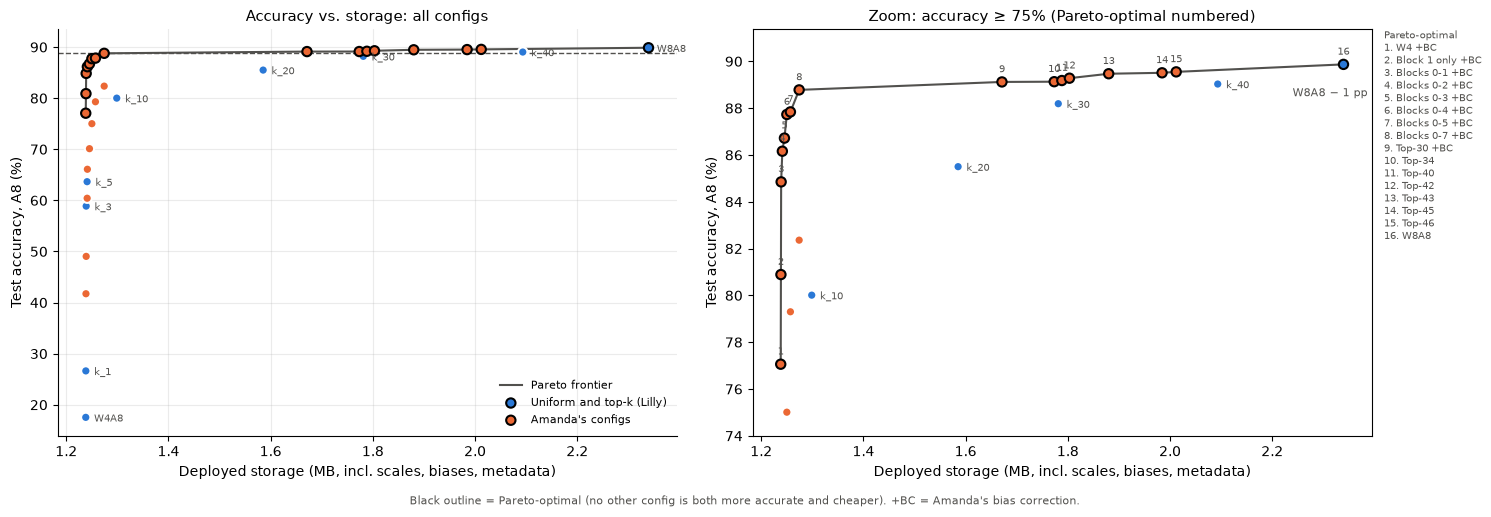

SKIP: no NeuroSim energy results yet, so accuracy_energy_pareto.png was not made.
Pareto-optimal (storage): W8A8, Uniform | W4 + bias correction, Whole blocks + bias correction | Block 1 only, Whole blocks + bias correction | Blocks 0-1, Whole blocks + bias correction | Blocks 0-2, Whole blocks + bias correction | Blocks 0-3, Whole blocks + bias correction | Blocks 0-4, Whole blocks + bias correction | Blocks 0-5, Whole blocks + bias correction | Blocks 0-7, Top-k + bias correction | Top-30, Top-k | Top-34, Top-k | Top-40, Top-k | Top-42, Top-k | Top-43, Top-k | Top-45, Top-k | Top-46


In [14]:
SOURCE_COLOR = {"uniform": "#2a78d6", "lilly": "#2a78d6", "amanda": "#eb6834"}
SOURCE_LABEL = {"lilly": "Uniform and top-k (Lilly)", "amanda": "Amanda's configs"}
INK = "#52514e"
ZOOM_MIN_ACC = 75     # the right-hand panel zooms in on configs at or above this accuracy


def pareto_mask(acc, cost):
    acc, cost = np.asarray(acc, float), np.asarray(cost, float)
    ok = ~np.isnan(acc) & ~np.isnan(cost)
    mask = np.zeros(len(acc), dtype=bool)
    for i in np.where(ok)[0]:
        dominated = ok & (acc >= acc[i]) & (cost <= cost[i]) & ((acc > acc[i]) | (cost < cost[i]))
        mask[i] = not dominated.any()
    return mask


def short_label(name):
    # 'Whole blocks + bias correction | Blocks 0-5' -> 'Blocks 0-5 +BC'
    bc = "bias correction" in name
    label = name.split("|")[-1].replace(" + bias correction", "").strip()
    return label + (" +BC" if bc else "")


def draw(ax, df, cost_col, label_all, numbered=False):
    front = df[df["pareto"]].sort_values(cost_col)
    ax.plot(front[cost_col], front["accuracy_pct"], color=INK, lw=1.5, zorder=2, label="Pareto frontier")
    for src in ["lilly", "amanda"]:
        part = df[df["source"].replace({"uniform": "lilly"}) == src]
        if len(part):
            ax.scatter(part[cost_col], part["accuracy_pct"], s=45, color=SOURCE_COLOR[src],
                       edgecolor=np.where(part["pareto"], "black", "white"), linewidth=1.5,
                       zorder=3, label=SOURCE_LABEL[src])
    if numbered:   # number the Pareto points (cheapest first); the key is printed beside the plot
        for i, (_, r) in enumerate(front.iterrows(), start=1):
            ax.annotate(str(i), (r[cost_col], r["accuracy_pct"]), textcoords="offset points",
                        xytext=(0, 7), ha="center", fontsize=7.5, color=INK)
        for _, r in df[~df["pareto"] & (df["source"] != "amanda")].iterrows():
            ax.annotate(short_label(r["config"]), (r[cost_col], r["accuracy_pct"]),
                        textcoords="offset points", xytext=(6, -3), fontsize=7.5, color=INK)
        return [f"{i}. {short_label(c)}" for i, c in enumerate(front["config"], start=1)]
    for _, r in df.iterrows():
        if label_all and r["source"] != "amanda":
            ax.annotate(short_label(r["config"]), (r[cost_col], r["accuracy_pct"]),
                        textcoords="offset points", xytext=(6, -3), fontsize=7.5, color=INK)
    ax.axhline(w8_acc - ONE_PP, color=INK, ls="--", lw=1)
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def pareto_figure(df, cost_col, xlabel, title, filename):
    df = df.dropna(subset=["accuracy_pct", cost_col]).copy()
    df["pareto"] = pareto_mask(df["accuracy_pct"], df[cost_col])
    fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(15, 5))
    draw(ax_all, df, cost_col, label_all=True)
    ax_all.set_title(f"{title}: all configs", fontsize=11)
    zoom = df[df["accuracy_pct"] >= ZOOM_MIN_ACC]
    key = draw(ax_zoom, zoom, cost_col, label_all=False, numbered=True)
    if len(zoom):
        ax_zoom.set_ylim(ZOOM_MIN_ACC - 1, max(zoom["accuracy_pct"].max(), w8_acc) + 1.5)
    ax_zoom.set_title(f"Zoom: accuracy ≥ {ZOOM_MIN_ACC}% (Pareto-optimal numbered)", fontsize=11)
    ax_zoom.text(1.02, 1.0, "Pareto-optimal\n" + "\n".join(key), transform=ax_zoom.transAxes,
                 va="top", fontsize=7.5, color=INK)
    ax_zoom.text(ax_zoom.get_xlim()[1], w8_acc - ONE_PP, "W8A8 − 1 pp ", ha="right", va="top", fontsize=8, color=INK)
    for ax in (ax_all, ax_zoom):
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Test accuracy, A8 (%)")
    ax_all.legend(fontsize=8, frameon=False, loc="lower right")
    fig.text(0.5, -0.02, "Black outline = Pareto-optimal (no other config is both more accurate and cheaper). "
             "+BC = Amanda's bias correction.", ha="center", fontsize=8, color=INK)
    fig.tight_layout()
    path = os.path.join(OUT_DIR, filename)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    FILES_WRITTEN.append(path)
    plt.show()
    return df


PARETO_TABLES = {}
per_config = final.drop_duplicates("config")
PARETO_TABLES["storage"] = pareto_figure(per_config, "total_MB", "Deployed storage (MB, incl. scales, biases, metadata)",
                                         "Accuracy vs. storage", "accuracy_storage_pareto.png")

if hw is None or "energy" not in final.columns or final["energy"].notna().sum() == 0:
    print("SKIP: no NeuroSim energy results yet, so accuracy_energy_pareto.png was not made.")
else:
    sim = final[final["energy"].notna()]
    for mapping in sorted(sim["depthwise_mapping"].unique()):
        suffix = "" if sim["depthwise_mapping"].nunique() == 1 else f"_{mapping}"
        PARETO_TABLES[f"energy_{mapping}"] = pareto_figure(
            sim[sim["depthwise_mapping"] == mapping], "energy", f"Energy per image ({HW_LABELS['energy']})",
            f"Accuracy vs. energy (depthwise: {mapping})", f"accuracy_energy_pareto{suffix}.png")

for name, table in PARETO_TABLES.items():
    print(f"Pareto-optimal ({name}): {', '.join(table.loc[table['pareto'], 'config'])}")

## 12. Does raising k recover accuracy while keeping useful savings?

In [15]:
topk = final[final["k"].notna()].drop_duplicates(["config", "depthwise_mapping"]).sort_values(["k", "depthwise_mapping"])
cols = ["config", "depthwise_mapping", "accuracy_pct", "accuracy_vs_W8A8_pp", "storage_vs_W8A8_pct"]
cols += [c for c in ["energy_vs_W8A8_pct", "latency_vs_W8A8_pct", "area_vs_W8A8_pct"] if c in topk.columns]
print(topk[cols].round(2).to_string(index=False))

ks = final[final["config"].str.startswith("k_")].drop_duplicates("config").sort_values("k")
passing = ks[ks["within_1pp_of_W8A8"]]
print()
if len(passing):
    best = passing.iloc[0]
    print(f"Smallest tested k within {ONE_PP} pp of W8A8: {best['config']} "
          f"({best['accuracy_pct']:.2f}% vs {w8_acc:.2f}%, storage {best['storage_vs_W8A8_pct']:+.1f}% vs W8A8)")
    rows = final[final["config"] == best["config"]]
    if "energy_vs_W8A8_pct" in rows and rows["energy_vs_W8A8_pct"].notna().any():
        for _, r in rows.iterrows():
            print(f"  energy vs W8A8 ({r['depthwise_mapping']}): {r['energy_vs_W8A8_pct']:+.1f}%")
    else:
        print("  No simulated energy for this config yet.")
elif len(ks):
    closest = ks.loc[ks["accuracy_vs_W8A8_pp"].idxmax()]
    print(f"NEGATIVE RESULT: no tested k is within {ONE_PP} pp of W8A8 ({w8_acc:.2f}%). "
          f"Closest is {closest['config']} at {closest['accuracy_pct']:.2f}% "
          f"({closest['accuracy_vs_W8A8_pp']:+.2f} pp). Report the full Pareto frontier above.")
else:
    print("No top-k configs loaded yet.")
print("\nEnergy differences above come only from configs Dana simulated. "
      "Uniform W4A8 savings are the best case, not the expected mixed-precision saving.")

config depthwise_mapping  accuracy_pct  accuracy_vs_W8A8_pp  storage_vs_W8A8_pct
  W4A8     not_simulated         17.54               -72.33               -47.08
   k_1     not_simulated         26.63               -63.24               -47.07
   k_3     not_simulated         58.88               -30.99               -47.04
   k_5     not_simulated         63.66               -26.21               -46.96
  k_10     not_simulated         80.01                -9.86               -44.48
  k_20     not_simulated         85.50                -4.37               -32.24
  k_30     not_simulated         88.19                -1.68               -23.86
  k_40     not_simulated         89.03                -0.84               -10.52
  W8A8     not_simulated         89.87                 0.00                 0.00

Smallest tested k within 1.0 pp of W8A8: k_40 (89.03% vs 89.87%, storage -10.5% vs W8A8)
  No simulated energy for this config yet.

Energy differences above come only from configs Dana sim

## 13. Summary

In [16]:
summary_cols = ["config", "depthwise_mapping", "accuracy_pct", "accuracy_vs_W8A8_pp", "total_MB", "storage_vs_W8A8_pct"]
summary_cols += [c for c in ["energy", "energy_vs_W8A8_pct", "latency_vs_W8A8_pct", "area_vs_W8A8_pct"] if c in final.columns]
print(f"Activation quantizer: {ACT_QUANTIZER} (A{ACT_BITS}) | calibration: {CALIB_IMAGES} training images | device: {device}\n")
print(final[summary_cols].round(3).to_string(index=False))
if missing_k:
    print(f"\nStill missing from Lilly's configs: k = {missing_k}")
print("\nFiles written:")
for path in FILES_WRITTEN:
    print("  " + os.path.relpath(path, REPO_DIR))

Activation quantizer: lilly (A8) | calibration: 2048 training images | device: mps

                                       config depthwise_mapping  accuracy_pct  accuracy_vs_W8A8_pp  total_MB  storage_vs_W8A8_pct
                                         W8A8     not_simulated         89.87                 0.00     2.339                0.000
                                         k_40     not_simulated         89.03                -0.84     2.093              -10.519
                                         k_30     not_simulated         88.19                -1.68     1.781              -23.857
                                         k_20     not_simulated         85.50                -4.37     1.585              -32.237
                                         k_10     not_simulated         80.01                -9.86     1.299              -44.482
                                          k_5     not_simulated         63.66               -26.21     1.241              -46.963
      